# EventMate — AI Event Planner

EventMate helps students, families, and university groups organize birthdays, parties, and campus events. It creates event plans, manages guest lists, estimates budgets, checks outdoor weather with Open-Meteo, and checks public holidays with Nager.Date. It pauses before cancellation and waits for a human decision.

## Objectives and users

The target users are people organizing small social or university events. This project demonstrates LangChain tools, ChatGroq tool selection, LangGraph StateGraph routing, thread memory, two real external APIs, and a real approval interruption.

## Assignment sources

The assignment PDF sets the grading requirements. This starter notebook asks for two real external services, so this project includes Open-Meteo and Nager.Date. The completed test outcomes below must be filled only after running the cells; no successful output is claimed in advance.

## How to run

Run each code cell from top to bottom with **Shift+Enter**. The install and key cells must be run in a fresh Colab runtime. Configure the `GROQ_API_KEY` secret before running model calls.


## 1. Install packages

Run this cell in a fresh Google Colab session and wait until it finishes.

In [28]:
%pip install -q langchain-core==1.8.4 langchain-groq==1.2.1 langgraph==1.2.24 requests==2.34.2


## 2. Load the Groq API key securely

Add `GROQ_API_KEY` in Colab's left-side **Secrets** panel, enable notebook access, and run this cell. The key is never printed.

In [29]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
assert os.environ["GROQ_API_KEY"], "Add GROQ_API_KEY in Colab Secrets first."
print("Groq key loaded securely.")


Groq key loaded securely.


## 3. Agent implementation

The following cell defines the State, event store, documented tools, model, assistant and tools nodes, conditional routing, and compiled graph builder. `assistant` asks ChatGroq to answer or select tools. `tools` executes requested functions and returns tool messages. `InMemorySaver` stores conversation state for the same `thread_id`. Event details use the thread ID as a storage key so different conversations do not share events. `interrupt()` stops cancellation before it changes data.

In [30]:
"""AI Event Planner: a beginner-friendly LangGraph assistant.

Events and guests are held in memory and isolated by LangGraph thread ID. The
checkpointer also keeps conversation history and pauses safely before canceling.
"""

from __future__ import annotations

import os
import json
import threading
import uuid
from datetime import date
from typing import Any, Annotated, TypedDict

import requests
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.runnables import RunnableConfig
from langchain_core.tools import tool
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.types import interrupt

DEFAULT_MODEL = "openai/gpt-oss-20b"
OPEN_METEO_GEOCODING_URL = "https://geocoding-api.open-meteo.com/v1/search"
OPEN_METEO_FORECAST_URL = "https://api.open-meteo.com/v1/forecast"
NAGER_HOLIDAYS_URL = "https://date.nager.at/api/v3/PublicHolidays"
REQUEST_TIMEOUT = 15


class AgentState(TypedDict):
    """Graph state: messages are accumulated to preserve conversation history."""

    messages: Annotated[list[AnyMessage], add_messages]


class EventStore:
    """Small thread-safe memory store, partitioned by conversation thread ID."""

    def __init__(self) -> None:
        self._events: dict[str, dict[str, dict[str, Any]]] = {}
        self._lock = threading.RLock()

    def list_events(self, thread_id: str) -> list[dict[str, Any]]:
        with self._lock:
            return [dict(item, guests=list(item["guests"])) for item in self._events.get(thread_id, {}).values()]

    def create_event(self, thread_id: str, event: dict[str, Any]) -> dict[str, Any]:
        with self._lock:
            self._events.setdefault(thread_id, {})[event["event_id"]] = event
            return dict(event, guests=list(event["guests"]))

    def add_guest(self, thread_id: str, event_id: str, guest: dict[str, Any]) -> dict[str, Any] | None:
        with self._lock:
            event = self._events.get(thread_id, {}).get(event_id)
            if event is None:
                return None
            event["guests"].append(guest)
            return dict(guest)

    def get_event(self, thread_id: str, event_id: str) -> dict[str, Any] | None:
        with self._lock:
            event = self._events.get(thread_id, {}).get(event_id)
            return dict(event, guests=list(event["guests"])) if event else None

    def cancel_event(self, thread_id: str, event_id: str) -> bool:
        with self._lock:
            events = self._events.get(thread_id, {})
            return events.pop(event_id, None) is not None


def _thread_id(config: RunnableConfig | None) -> str:
    """Read the isolated conversation ID supplied by LangGraph."""
    configurable = (config or {}).get("configurable", {})
    return str(configurable.get("thread_id", "default"))


def _parse_event_date(value: str) -> date:
    """Validate an ISO date and return a useful error for the model/user."""
    try:
        return date.fromisoformat(value)
    except (TypeError, ValueError) as exc:
        raise ValueError("Use a valid date in YYYY-MM-DD format.") from exc


def create_tools(store: EventStore) -> list[Any]:
    """Create LangChain tools that all use the same session-isolated store."""

    @tool
    def create_event(
        name: str,
        event_date: str,
        city: str,
        venue_type: str = "indoor",
        budget: float = 0,
        currency: str = "USD",
        *,
        config: RunnableConfig,
    ) -> dict[str, Any]:
        """Create an event plan with its date, city, venue type, and budget."""
        if not name.strip() or not city.strip():
            raise ValueError("Event name and city must not be empty.")
        parsed_date = _parse_event_date(event_date)
        if budget < 0:
            raise ValueError("Budget must be zero or more.")
        normalized_venue = venue_type.strip().lower()
        if normalized_venue not in {"indoor", "outdoor"}:
            raise ValueError("venue_type must be 'indoor' or 'outdoor'.")
        event = {
            "event_id": str(uuid.uuid4())[:8],
            "name": name.strip(),
            "date": parsed_date.isoformat(),
            "city": city.strip(),
            "venue_type": normalized_venue,
            "budget": round(float(budget), 2),
            "currency": currency.strip().upper() or "USD",
            "guests": [],
        }
        return store.create_event(_thread_id(config), event)

    @tool
    def add_guest(
        event_id: str,
        name: str,
        email: str = "",
        *,
        config: RunnableConfig,
    ) -> dict[str, Any]:
        """Add a named guest to an existing event using its event ID."""
        if not name.strip():
            raise ValueError("Guest name must not be empty.")
        guest = {"name": name.strip(), "email": email.strip()}
        result = store.add_guest(_thread_id(config), event_id.strip(), guest)
        if result is None:
            return {"error": f"No event found with ID {event_id!r} in this conversation."}
        return {"event_id": event_id, "guest": result}

    @tool
    def list_events(config: RunnableConfig) -> list[dict[str, Any]]:
        """List this conversation's events and their guest lists."""
        return store.list_events(_thread_id(config))

    @tool
    def calculate_budget(total_budget: float, guest_count: int, categories: str = "food,decorations,venue") -> dict[str, Any]:
        """Split an event budget evenly across comma-separated spending categories."""
        if total_budget < 0 or guest_count < 0:
            raise ValueError("Budget and guest count must not be negative.")
        names = [part.strip() for part in categories.split(",") if part.strip()]
        if not names:
            raise ValueError("Provide at least one budget category.")
        each = round(float(total_budget) / len(names), 2)
        return {
            "total_budget": round(float(total_budget), 2),
            "guest_count": guest_count,
            "per_guest_budget": round(float(total_budget) / guest_count, 2) if guest_count else None,
            "category_estimates": {name: each for name in names},
        }

    @tool
    def get_weather(city: str, event_date: str) -> dict[str, Any]:
        """Get a real Open-Meteo forecast for an outdoor event's city and date."""
        target_date = _parse_event_date(event_date)
        try:
            location_response = requests.get(
                OPEN_METEO_GEOCODING_URL,
                params={"name": city.strip(), "count": 1, "language": "en", "format": "json"},
                timeout=REQUEST_TIMEOUT,
            )
            location_response.raise_for_status()
            locations = location_response.json().get("results", [])
            if not locations:
                return {"error": f"Open-Meteo could not find the city {city!r}."}
            place = locations[0]
            forecast_response = requests.get(
                OPEN_METEO_FORECAST_URL,
                params={
                    "latitude": place["latitude"],
                    "longitude": place["longitude"],
                    "daily": "temperature_2m_max,precipitation_probability_max,weather_code",
                    "timezone": "auto",
                    "start_date": target_date.isoformat(),
                    "end_date": target_date.isoformat(),
                },
                timeout=REQUEST_TIMEOUT,
            )
            forecast_response.raise_for_status()
            daily = forecast_response.json().get("daily", {})
            if not daily.get("time"):
                return {"error": "Open-Meteo returned no forecast for that date. Forecast dates are limited."}
            return {
                "city": place.get("name", city),
                "country": place.get("country"),
                "date": daily["time"][0],
                "temperature_max_c": daily.get("temperature_2m_max", [None])[0],
                "precipitation_probability_max_percent": daily.get("precipitation_probability_max", [None])[0],
                "weather_code": daily.get("weather_code", [None])[0],
                "source": "Open-Meteo",
            }
        except requests.RequestException as exc:
            return {"error": f"Weather service request failed: {exc.__class__.__name__}. Please try again."}
        except (ValueError, KeyError, IndexError, TypeError) as exc:
            return {"error": f"Weather service returned unexpected data: {exc.__class__.__name__}."}

    @tool
    def get_public_holidays(country_code: str, year: int) -> list[dict[str, Any]] | dict[str, str]:
        """Look up real public holiday dates for a two-letter country code using Nager.Date."""
        code = country_code.strip().upper()
        if len(code) != 2 or not code.isalpha():
            raise ValueError("Use a two-letter country code, such as GE, US, or GB.")
        if year < 1900 or year > 2100:
            raise ValueError("Year must be between 1900 and 2100.")
        try:
            response = requests.get(f"{NAGER_HOLIDAYS_URL}/{year}/{code}", timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            data = response.json()
            if not isinstance(data, list):
                return {"error": "Holiday service returned an unexpected response."}
            return [{"date": item.get("date"), "name": item.get("localName") or item.get("name")} for item in data]
        except requests.RequestException as exc:
            return {"error": f"Holiday service request failed: {exc.__class__.__name__}. Please try again."}

    @tool
    def cancel_event(event_id: str, config: RunnableConfig) -> dict[str, Any]:
        """Cancel an event only after the human approves the LangGraph interruption."""
        thread_id = _thread_id(config)
        event = store.get_event(thread_id, event_id.strip())
        if event is None:
            return {"error": f"No event found with ID {event_id!r} in this conversation."}
        decision = interrupt(
            {
                "action": "cancel_event",
                "event_id": event["event_id"],
                "event_name": event["name"],
                "event_date": event["date"],
                "message": f"Cancel {event['name']!r} on {event['date']}? Approve or reject this action.",
            }
        )
        approved = decision is True or (isinstance(decision, dict) and decision.get("approved") is True)
        if not approved:
            return {"status": "cancelled_by_user", "event_id": event["event_id"], "event_kept": True}
        removed = store.cancel_event(thread_id, event["event_id"])
        return {"status": "event_cancelled" if removed else "event_not_found", "event_id": event["event_id"]}

    return [create_event, add_guest, list_events, calculate_budget, get_weather, get_public_holidays, cancel_event]


def build_graph(
    *,
    model_name: str | None = None,
    checkpointer: Any | None = None,
    event_store: EventStore | None = None,
    model: Any | None = None,
) -> Any:
    """Build and compile the assistant graph. Pass a fake model only in unit tests."""
    if model is None:
        if not os.environ.get("GROQ_API_KEY"):
            raise RuntimeError("GROQ_API_KEY is missing. Set it in your environment or Colab/Streamlit Secrets.")
        from langchain_groq import ChatGroq

        model = ChatGroq(model=model_name or DEFAULT_MODEL, temperature=0, max_tokens=700, max_retries=2)

    store = event_store or EventStore()
    tools = create_tools(store)
    tools_by_name = {item.name: item for item in tools}
    model_with_tools = model.bind_tools(tools)
    system_message = SystemMessage(
        content=(
            "You are EventMate, a friendly AI Event Planner for students and families. "
            "Plan birthdays, parties, and university events. Ask for missing required details before creating an event. "
            "Use tools for saved event data, real weather, and public holiday lookups. Explain estimates clearly. "
            "Never claim a forecast or holiday lookup succeeded unless its tool returned data. "
            "Before cancel_event, call the tool; it will pause and ask the human for approval. Do not say an event "
            "was cancelled until the tool returns event_cancelled. A rejected request leaves the event saved. "
            "Use the event ID returned by create_event when adding guests or cancelling. Keep replies concise and clear."
        )
    )

    def assistant_node(state: AgentState) -> dict[str, list[AnyMessage]]:
        answer = model_with_tools.invoke([system_message, *state["messages"]])
        return {"messages": [answer]}

    def tools_node(state: AgentState, config: RunnableConfig) -> dict[str, list[AnyMessage]]:
        last = state["messages"][-1]
        tool_messages: list[ToolMessage] = []
        for call in last.tool_calls:
            selected = tools_by_name.get(call["name"])
            if selected is None:
                content: Any = {"error": f"Unknown tool: {call['name']}"}
            else:
                try:
                    content = selected.invoke(call.get("args", {}), config=config)
                except (ValueError, requests.RequestException) as exc:
                    content = {"error": str(exc)}
            tool_messages.append(
                ToolMessage(
                    content=json.dumps(content, ensure_ascii=False, default=str),
                    tool_call_id=call["id"],
                    name=call["name"],
                )
            )
        return {"messages": tool_messages}

    def route_after_assistant(state: AgentState) -> str:
        return "tools" if isinstance(state["messages"][-1], AIMessage) and state["messages"][-1].tool_calls else END

    builder = StateGraph(AgentState)
    builder.add_node("assistant", assistant_node)
    builder.add_node("tools", tools_node)
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", route_after_assistant, {"tools": "tools", END: END})
    builder.add_edge("tools", "assistant")
    return builder.compile(checkpointer=checkpointer or InMemorySaver())


def new_thread_config(thread_id: str | None = None) -> dict[str, Any]:
    """Return a LangGraph config for a new or existing conversation."""
    return {"configurable": {"thread_id": thread_id or str(uuid.uuid4())}}


def pending_interrupt(result: dict[str, Any]) -> dict[str, Any] | None:
    """Return the first interrupt payload from an invoke result, when present."""
    interruptions = result.get("__interrupt__", ())
    if interruptions:
        value = getattr(interruptions[0], "value", interruptions[0])
        return value if isinstance(value, dict) else {"message": str(value)}
    return None


def latest_assistant_text(result: dict[str, Any]) -> str:
    """Find the newest human-readable assistant message in a graph result."""
    for message in reversed(result.get("messages", [])):
        if isinstance(message, AIMessage) and isinstance(message.content, str) and message.content.strip():
            return message.content
    return "The agent finished without a text response."


__all__ = [
    "AgentState", "EventStore", "build_graph", "create_tools", "latest_assistant_text",
    "new_thread_config", "pending_interrupt",
]


## 4. Build the graph and show its diagram

This graph routes from `START` to the assistant, sends tool calls to the tools node, returns tool results to the assistant, and ends after a normal answer.

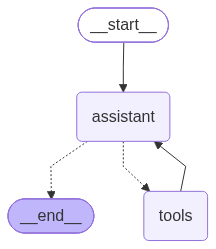

In [31]:
from IPython.display import Image, display
from langchain_core.messages import HumanMessage
from langgraph.types import Command

event_store = EventStore()
graph = build_graph(event_store=event_store)
thread_id = "eventmate-colab-demo"
config = {"configurable": {"thread_id": thread_id}}

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print("Graph rendering needs a working Mermaid rendering connection:", type(error).__name__)
    print(graph.get_graph().draw_mermaid())


## 5. Reusable trajectory display

This helper prints each graph message so the tool calls and tool responses are visible.

In [32]:
def show_trajectory(result):
    for message in result.get("messages", []):
        message.pretty_print()
    pending = pending_interrupt(result)
    if pending:
        print("\nAPPROVAL REQUIRED:", pending)
    return pending

def ask_agent(query, expected_tools=(), thread_config=config):
    print("USER QUERY:", query)
    result = graph.invoke({"messages": [HumanMessage(content=query)]}, thread_config)
    pending = show_trajectory(result)
    calls = [call for message in result.get("messages", []) for call in getattr(message, "tool_calls", [])]
    names = [call["name"] for call in calls]
    print("TOOL CALLS:", names if names else "none")
    print("ACTUAL RESULT:", pending.get("message") if pending else latest_assistant_text(result))
    if expected_tools:
        passed = set(expected_tools).issubset(set(names))
        print("PASS/FAIL:", "PASS" if passed else "FAIL", "expected:", sorted(expected_tools))
    return result


## 6. Individual tool checks

These checks exercise event storage, guest management, and budget arithmetic locally. External-service cells below call the real public APIs.

In [33]:
tools_by_name = {tool.name: tool for tool in create_tools(event_store)}
tool_config = {"configurable": {"thread_id": "eventmate-tool-checks"}}
created = tools_by_name["create_event"].invoke(
    {"name": "Tool check dinner", "event_date": "2026-12-20", "city": "Tbilisi", "venue_type": "indoor", "budget": 400, "currency": "GEL"},
    config=tool_config,
)
print("CREATE EVENT RESULT:", created)
guest_result = tools_by_name["add_guest"].invoke(
    {"event_id": created["event_id"], "name": "Nino", "email": ""}, config=tool_config
)
print("ADD GUEST RESULT:", guest_result)
print("LIST EVENTS RESULT:", tools_by_name["list_events"].invoke({}, config=tool_config))
print("BUDGET RESULT:", tools_by_name["calculate_budget"].invoke(
    {"total_budget": 400, "guest_count": 8, "categories": "food,decorations,venue"}
))


CREATE EVENT RESULT: {'event_id': '388a49b2', 'name': 'Tool check dinner', 'date': '2026-12-20', 'city': 'Tbilisi', 'venue_type': 'indoor', 'budget': 400.0, 'currency': 'GEL', 'guests': []}
ADD GUEST RESULT: {'event_id': '388a49b2', 'guest': {'name': 'Nino', 'email': ''}}
LIST EVENTS RESULT: [{'event_id': '388a49b2', 'name': 'Tool check dinner', 'date': '2026-12-20', 'city': 'Tbilisi', 'venue_type': 'indoor', 'budget': 400.0, 'currency': 'GEL', 'guests': [{'name': 'Nino', 'email': ''}]}]
BUDGET RESULT: {'total_budget': 400.0, 'guest_count': 8, 'per_guest_budget': 50.0, 'category_estimates': {'food': 133.33, 'decorations': 133.33, 'venue': 133.33}}


## 7. Test query 1 — Create an event

Expected: the agent calls `create_event`, saves a plan, and returns its ID. Run this cell to record the actual trajectory.

In [34]:
result_create = ask_agent('Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.', {'create_event'})


USER QUERY: Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.
================================ Human Message =================================

Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.
================================== Ai Message ==================================

Could you let me know the name you’d like for the university welcome party? Once I have that, I’ll create the event.
TOOL CALLS: none
ACTUAL RESULT: Could you let me know the name you’d like for the university welcome party? Once I have that, I’ll create the event.
PASS/FAIL: FAIL expected: ['create_event']


## 8. Test query 2 — Remember the event and add a guest

Expected: the same thread can list the event created above and add the named guest.

In [35]:
result_guest = ask_agent('Add Ana to the university welcome party, then show me the event and guest list.', {'add_guest'})


USER QUERY: Add Ana to the university welcome party, then show me the event and guest list.
================================ Human Message =================================

Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.
================================== Ai Message ==================================

Could you let me know the name you’d like for the university welcome party? Once I have that, I’ll create the event.
================================ Human Message =================================

Add Ana to the university welcome party, then show me the event and guest list.
================================== Ai Message ==================================

I’ll need the event name first. Could you tell me what you’d like to call the university welcome party? Once I have that, I’ll create the event, add Ana, and then show you the event and guest list.
TOOL CALLS: none
ACTUAL RESULT: I’ll need the event name first. Could you tell me w

## 9. Test query 3 — Real weather request

Expected: the agent calls Open-Meteo and reports a forecast for the requested city and date, or clearly reports that date is outside the forecast range.

In [36]:
result_weather = ask_agent('Check the real weather forecast for Tbilisi on 2026-11-25. This is an outdoor event.', {'get_weather'})


USER QUERY: Check the real weather forecast for Tbilisi on 2026-11-25. This is an outdoor event.
================================ Human Message =================================

Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.
================================== Ai Message ==================================

Could you let me know the name you’d like for the university welcome party? Once I have that, I’ll create the event.
================================ Human Message =================================

Add Ana to the university welcome party, then show me the event and guest list.
================================== Ai Message ==================================

I’ll need the event name first. Could you tell me what you’d like to call the university welcome party? Once I have that, I’ll create the event, add Ana, and then show you the event and guest list.
================================ Human Message ===============================

## 10. Test query 4 — Real public holiday request

Expected: the agent calls Nager.Date and returns the matching holiday information or an API/coverage error.

In [37]:
result_holiday = ask_agent('Check public holidays in Georgia for 2026 and tell me whether December 10 is a listed holiday.', {'get_public_holidays'})


USER QUERY: Check public holidays in Georgia for 2026 and tell me whether December 10 is a listed holiday.
================================ Human Message =================================

Create a university welcome party on 2026-11-25 in Tbilisi. It is outdoors and the budget is 500 GEL.
================================== Ai Message ==================================

Could you let me know the name you’d like for the university welcome party? Once I have that, I’ll create the event.
================================ Human Message =================================

Add Ana to the university welcome party, then show me the event and guest list.
================================== Ai Message ==================================

I’ll need the event name first. Could you tell me what you’d like to call the university welcome party? Once I have that, I’ll create the event, add Ana, and then show you the event and guest list.
================================ Human Message =====================

## 11. Test query 5 — Request event cancellation

Expected: the graph pauses before cancellation and shows the event name/date. This cell does not resume automatically. Read the interruption before you continue.

In [38]:
approval_config = {"configurable": {"thread_id": "eventmate-approve-demo"}}
approval_tools = {tool.name: tool for tool in create_tools(event_store)}
approval_event = approval_tools["create_event"].invoke(
    {"name": "Approved cancellation demo", "event_date": "2026-12-22", "city": "Tbilisi", "venue_type": "indoor", "budget": 100, "currency": "GEL"},
    config=approval_config,
)
approval_query = f"Please cancel event {approval_event['event_id']} called Approved cancellation demo. Ask for my approval before cancelling."
approved_paused = ask_agent(approval_query, {"cancel_event"}, approval_config)


USER QUERY: Please cancel event 74d44abe called Approved cancellation demo. Ask for my approval before cancelling.
================================ Human Message =================================

Please cancel event 74d44abe called Approved cancellation demo. Ask for my approval before cancelling.
================================== Ai Message ==================================
Tool Calls:
  cancel_event (fc_da13403e-9cee-4c77-af8a-25e8133ad883)
 Call ID: fc_da13403e-9cee-4c77-af8a-25e8133ad883
  Args:
    event_id: 74d44abe

APPROVAL REQUIRED: {'action': 'cancel_event', 'event_id': '74d44abe', 'event_name': 'Approved cancellation demo', 'event_date': '2026-12-22', 'message': "Cancel 'Approved cancellation demo' on 2026-12-22? Approve or reject this action."}
TOOL CALLS: ['cancel_event']
ACTUAL RESULT: Cancel 'Approved cancellation demo' on 2026-12-22? Approve or reject this action.
PASS/FAIL: PASS expected: ['cancel_event']


### INTERJECT HERE — Approve or stop

Check the event name and date printed above. To approve this demo cancellation, run the next cell. If you do not want to approve, skip it; the event is still saved. The separate rejection test below demonstrates `resume=False`.

In [39]:
assert pending_interrupt(approved_paused), "No approval pause was returned. Rerun the request cell with a clearer cancellation query."
print("RESUMING WITH YOUR APPROVAL: True")
approved_result = graph.invoke(Command(resume=True), approval_config)
show_trajectory(approved_result)
after_approval = event_store.list_events(approval_config["configurable"]["thread_id"])
print("ACTUAL RESULT:", latest_assistant_text(approved_result))
print("EVENTS AFTER APPROVAL:", after_approval)
print("PASS/FAIL:", "PASS" if not after_approval else "FAIL")


RESUMING WITH YOUR APPROVAL: True
================================ Human Message =================================

Please cancel event 74d44abe called Approved cancellation demo. Ask for my approval before cancelling.
================================== Ai Message ==================================
Tool Calls:
  cancel_event (fc_da13403e-9cee-4c77-af8a-25e8133ad883)
 Call ID: fc_da13403e-9cee-4c77-af8a-25e8133ad883
  Args:
    event_id: 74d44abe
================================= Tool Message =================================
Name: cancel_event

{"status": "event_cancelled", "event_id": "74d44abe"}
================================== Ai Message ==================================

Your event “Approved cancellation demo” has been cancelled.
ACTUAL RESULT: Your event “Approved cancellation demo” has been cancelled.
EVENTS AFTER APPROVAL: []
PASS/FAIL: PASS


## 12. Test query 6 — Request cancellation for rejection

Expected: the graph pauses and displays the exact event. This cell stops at the approval request.

In [42]:
reject_config = {"configurable": {"thread_id": "eventmate-reject-demo"}}
reject_tools = {tool.name: tool for tool in create_tools(event_store)}
reject_event = reject_tools["create_event"].invoke(
    {"name": "Rejected cancellation demo", "event_date": "2026-12-23", "city": "Tbilisi", "venue_type": "indoor", "budget": 120, "currency": "GEL"},
    config=reject_config,
)
reject_query = f"Cancel event {reject_event['event_id']} named Rejected cancellation demo. Ask me first."
rejected_paused = ask_agent(reject_query, {"cancel_event"}, reject_config)


USER QUERY: Cancel event ff470d6e named Rejected cancellation demo. Ask me first.
================================ Human Message =================================

Cancel event 8a071f2e named Rejected cancellation demo. Ask me first.
================================== Ai Message ==================================

Sure, I can help cancel the event.  
Would you like me to proceed with canceling the event “Rejected cancellation demo” (ID 8a071f2e)?
================================ Human Message =================================

Cancel event ff470d6e named Rejected cancellation demo. Ask me first.
================================== Ai Message ==================================
Tool Calls:
  cancel_event (fc_660b9df5-fd6d-4271-a788-b0ac17e7ad7b)
 Call ID: fc_660b9df5-fd6d-4271-a788-b0ac17e7ad7b
  Args:
    event_id: ff470d6e

APPROVAL REQUIRED: {'action': 'cancel_event', 'event_id': 'ff470d6e', 'event_name': 'Rejected cancellation demo', 'event_date': '2026-12-23', 'message': "Cancel 'Rej

### INTERJECT HERE — Reject cancellation

After checking the event details above, run the next cell to reject cancellation. It resumes with `Command(resume=False)` and verifies that the event remains saved.

In [43]:
assert pending_interrupt(rejected_paused), "No approval pause was returned. Rerun the request cell with a clearer cancellation query."
print("RESUMING WITH YOUR REJECTION: False")
rejected_result = graph.invoke(Command(resume=False), reject_config)
show_trajectory(rejected_result)
after_rejection = event_store.list_events(reject_config["configurable"]["thread_id"])
print("ACTUAL RESULT:", latest_assistant_text(rejected_result))
print("EVENTS AFTER REJECTION:", after_rejection)
print("PASS/FAIL:", "PASS" if len(after_rejection) == 1 else "FAIL")


RESUMING WITH YOUR REJECTION: False
================================ Human Message =================================

Cancel event 8a071f2e named Rejected cancellation demo. Ask me first.
================================== Ai Message ==================================

Sure, I can help cancel the event.  
Would you like me to proceed with canceling the event “Rejected cancellation demo” (ID 8a071f2e)?
================================ Human Message =================================

Cancel event ff470d6e named Rejected cancellation demo. Ask me first.
================================== Ai Message ==================================
Tool Calls:
  cancel_event (fc_660b9df5-fd6d-4271-a788-b0ac17e7ad7b)
 Call ID: fc_660b9df5-fd6d-4271-a788-b0ac17e7ad7b
  Args:
    event_id: ff470d6e
================================= Tool Message =================================
Name: cancel_event

{"status": "cancelled_by_user", "event_id": "ff470d6e", "event_kept": true}
================================== 

## Evaluation table

Initial status is **NOT RUN**. After you execute each cell, update the result and notes using its real output. The test 5 and 6 request cells stop at the approval point; inspect their output and then run the separate resume cells to approve or reject. The weather query is dated 2026-11-25, within the normal forecast window as of this notebook's preparation date; if you run later, adjust it to a date Open-Meteo supports.

| # | Query | Expected Result | Pass? | Notes |
|---|---|---|---|---|
| 1 | Create a university event | Event saved and ID returned | NOT RUN | Fill after running Test 1 |
| 2 | Add a guest and show the plan | Earlier event recalled; guest appears | NOT RUN | Fill after running Test 2 |
| 3 | Check event weather | Live Open-Meteo response or clear forecast-limit message | NOT RUN | Fill after running Test 3 |
| 4 | Check public holidays | Live Nager.Date result or clear API response | NOT RUN | Fill after running Test 4 |
| 5 | Cancel and approve | Interrupt appears; event is removed only after approval | NOT RUN | Fill after running Test 5 |
| 6 | Cancel and reject | Interrupt appears; event remains after rejection | NOT RUN | Fill after running Test 6 |

## Conclusions and known limitations

EventMate shows how a model can route through tools, how a graph preserves conversation state, and how a destructive action can pause for a human decision. It uses two external services. The graph's `InMemorySaver` and event store reset when the runtime stops. Open-Meteo forecasts are date-limited, and holiday coverage depends on country data. The agent also requires a working Groq account and model with tool-calling support.
